In [13]:
from tkinter import Variable
!pip install yfinance

  Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl.metadata (595 bytes)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 18.4 MB/s eta 0:00:00
Using cached protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl (456 kB)

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [52]:
import yfinance as yf, numpy as np, datetime as dt, matplotlib.pyplot as plt
from scipy.stats import norm

In [53]:
tickers = ['AAPL', 'NVDA' , 'AMZN', 'TSLA', 'GS' ]
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])

In [54]:
start = dt.datetime (2022,1,1)
end = dt.datetime.now()

df = yf.download(tickers, start, end, auto_adjust=False) ["Adj Close"]
df

[*********************100%***********************]  5 of 5 completed


Ticker,AAPL,AMZN,GS,NVDA,TSLA
Date,,,,,
2022-01-03,177.786407,170.404495,352.062195,29.992582,399.926666
2022-01-04,175.529999,167.522003,362.882416,29.165127,383.196655
2022-01-05,170.860931,164.356995,355.001007,27.486309,362.706665
2022-01-06,168.008667,163.253998,353.487152,28.057865,354.899994
2022-01-07,168.174728,162.554001,354.003632,27.130838,342.320007
...,...,...,...,...,...
2026-09-28,338.399994,246.149994,916.280029,228.860001,357.450012
2026-09-29,329.399994,246.669998,916.239990,227.210007,352.839996
2026-09-30,333.019989,249.149994,900.359985,228.380005,354.809998


In [55]:
returns = df.pct_change()
returns

Ticker,AAPL,AMZN,GS,NVDA,TSLA
Date,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN
2022-01-04,-0.012692,-0.016916,0.030734,-0.027589,-0.041833
2022-01-05,-0.026600,-0.018893,-0.021719,-0.057563,-0.053471
2022-01-06,-0.016693,-0.006711,-0.004264,0.020794,-0.021523
2022-01-07,0.000988,-0.004288,0.001461,-0.033040,-0.035447
...,...,...,...,...,...
2026-09-28,-0.007828,-0.014099,-0.020493,0.016839,-0.039397
2026-09-29,-0.026596,0.002113,-0.000044,-0.007210,-0.012897
2026-09-30,0.010990,0.010054,-0.017332,0.005149,0.005583


In [56]:
cov_matrix = returns.cov()
cov_matrix

Ticker,AAPL,AMZN,GS,NVDA,TSLA
Ticker,,,,,
AAPL,0.000316,0.000202,0.000132,0.000270,0.000311
AMZN,0.000202,0.000543,0.000178,0.000394,0.000392
GS,0.000132,0.000178,0.000331,0.000253,0.000263
NVDA,0.000270,0.000394,0.000253,0.001060,0.000573
TSLA,0.000311,0.000392,0.000263,0.000573,0.001408


In [57]:
avg_returns = returns.mean()
avg_returns

Ticker
AAPL    0.000686
AMZN    0.000597
GS      0.000955
NVDA    0.002251
TSLA    0.000637
dtype: float64

In [58]:
count = returns.count()
count

Ticker
AAPL    1191
AMZN    1191
GS      1191
NVDA    1191
TSLA    1191
dtype: int64

In [59]:
port_mean = avg_returns @ weights
port_std = np.sqrt(weights.T @cov_matrix @ weights)

In [65]:
port_mean

np.float64(0.001025246225172375)

In [63]:
port_std

np.float64(0.01958877159245473)

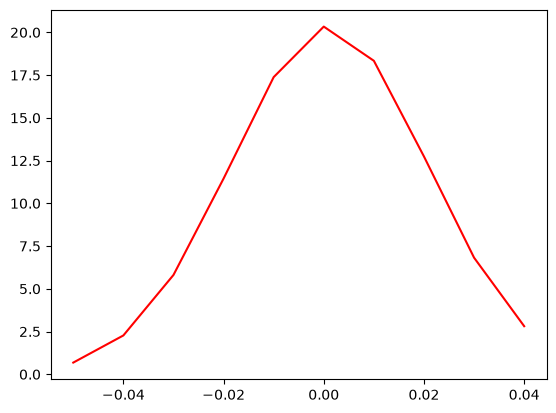

In [69]:
x = np.arange(-0.05, 0.05, 0.01)
norm_dist = norm.pdf(x, port_mean, port_std)
norm_dist


plt.plot(x, norm_dist, color = 'red')
plt.show()

In [78]:
confidence_level = 0.01

VaR = norm.ppf(confidence_level, port_mean, port_std)
VaR

np.float64(-0.0445450509240063)

In [80]:
num_days = 10

VaR * np.sqrt(num_days)

np.float64(-0.14086381940804796)

99.9, 10-day vaR = 14%

In [81]:
lower = port_mean - 2*port_std/np.sqrt(count)
higher = port_mean + 2*port_std/np.sqrt(count)

In [82]:
lower

Ticker
AAPL   -0.00011
AMZN   -0.00011
GS     -0.00011
NVDA   -0.00011
TSLA   -0.00011
dtype: float64

In [83]:
higher

Ticker
AAPL    0.00216
AMZN    0.00216
GS      0.00216
NVDA    0.00216
TSLA    0.00216
dtype: float64